<a href="https://colab.research.google.com/github/Jakir-Ai/telco-customer-churn-eda/blob/main/Telecom_Churn_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [2]:
# check dataset dimensions
print(f"shape :{df.shape}")
# SChema and memory usage
df.info()
# missing values audit
print("\nMissing values per column :")
print(df.isnull().sum())

shape :(7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 n

In [3]:
# Safe drop for customerID (only if present)
if 'customerID' in df.columns:
    df = df.drop(columns=['customerID'])

# Convert TotalCharges with exact capital 'C'
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Drop rows with NaN in TotalCharges
df = df.dropna(subset=['TotalCharges'])

# Verification
print("TotalCharges Dtype:", df['TotalCharges'].dtype)
print("Updated Shape:", df.shape)

TotalCharges Dtype: float64
Updated Shape: (7032, 20)


Churn counts:
 Churn
No     5163
Yes    1869
Name: count, dtype: int64

Churn percentage % :
 Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


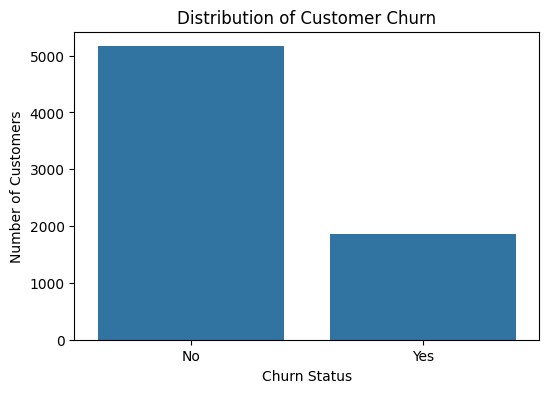

In [4]:
# Terget variable distribution (count and percentage)
print('Churn counts:\n', df['Churn'].value_counts())
# Churn percentage
print('\nChurn percentage % :\n',df['Churn'].value_counts(normalize=True)*100)
# Visualizing Target Distribution
plt.figure(figsize=(6,4))
sns.countplot(x='Churn',data= df)
plt.title('Distribution of Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.show()

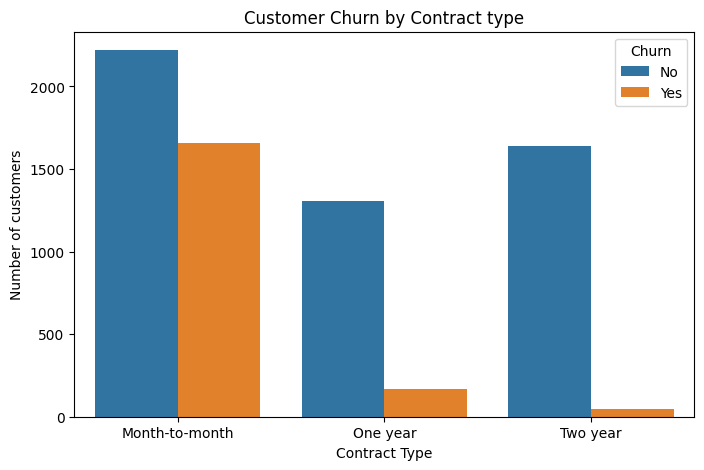

Churn % by Contract Type: 
Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.722826  11.277174
Two year        97.151335   2.848665


In [5]:
# Visualization: Contract Type vs Churn
plt.figure(figsize=(8,5))
sns.countplot(x='Contract',hue='Churn',data=df)
plt.title('Customer Churn by Contract type')
plt.xlabel('Contract Type')
plt.ylabel('Number of customers')
plt.show()
# Percentage table (Row-wise proportion)
print("Churn % by Contract Type: ")
print(pd.crosstab(df['Contract'],df['Churn'],normalize='index')*100)


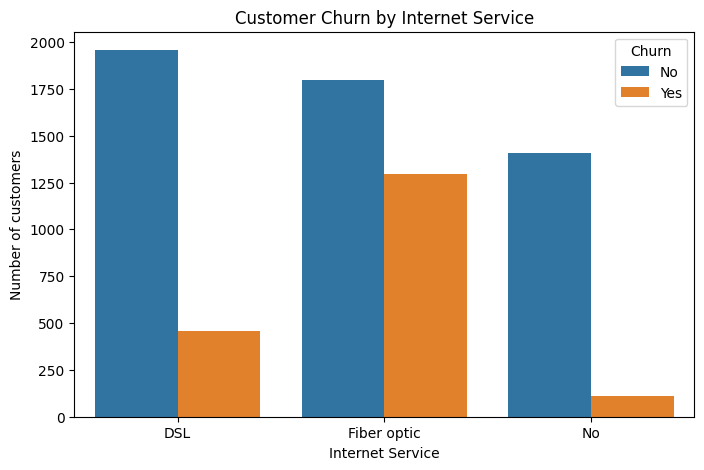

Churn % by internet service: 
Churn                   No        Yes
InternetService                      
DSL              81.001656  18.998344
Fiber optic      58.107235  41.892765
No               92.565789   7.434211


In [6]:
# Visualization : InternetService vs Churn
plt.figure(figsize=(8,5))
sns.countplot(x='InternetService',hue='Churn',data=df)
plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of customers')
plt.show()
# Percentage table
print('Churn % by internet service: ')
print(pd.crosstab(df['InternetService'],df['Churn'],normalize='index')*100)
#

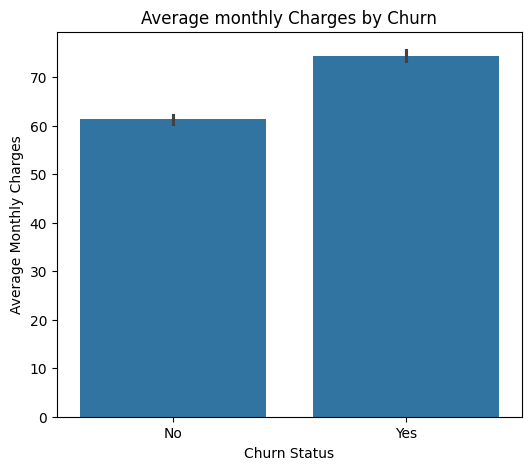

Average Monthly Charges by Churn: 
Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [7]:
# Visualization: Average Monthly CHarges by Churn Status
plt.figure(figsize=(6,5))
sns.barplot(x='Churn',y='MonthlyCharges',data=df)
plt.title('Average monthly Charges by Churn')
plt.xlabel('Churn Status')
plt.ylabel('Average Monthly Charges')
plt.show()
# Number Calculate (Average value)
print('Average Monthly Charges by Churn: ')
print(df.groupby('Churn')['MonthlyCharges'].mean())


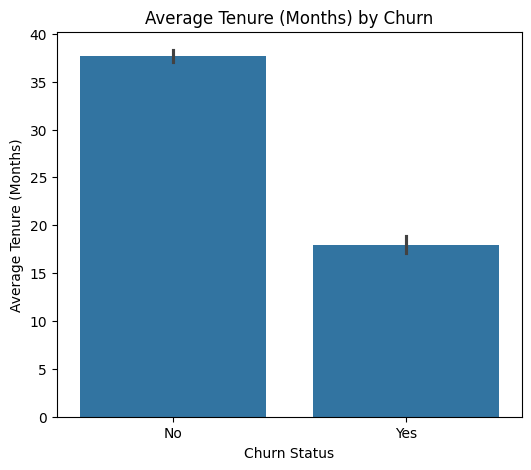

Average Tenure by Churn
Churn
No     37.650010
Yes    17.979133
Name: tenure, dtype: float64


In [8]:
# Visualization: Average Tenure by Churn
plt.figure(figsize=(6,5))
sns.barplot(x='Churn',y='tenure',data=df)
plt.title('Average Tenure (Months) by Churn')
plt.xlabel('Churn Status')
plt.ylabel('Average Tenure (Months)')
plt.show()
# Average Tenure Calculation
print('Average Tenure by Churn')
print(df.groupby('Churn')['tenure'].mean())

# Telecom Customer Churn - Exploratory Data Analysis (EDA)

## Project Overview
This project performs an in-depth Exploratory Data Analysis (EDA) on the Telco Customer Churn dataset to identify key drivers of customer attrition and provide actionable retention strategies.

## Key Insights
* **Overall Churn Rate:** Approximately 26.57% of customers have churned.
* **Contract Type:** Customers on **Month-to-Month** contracts exhibit the highest churn rate (~42.7%), whereas **Two-Year** contracts have the lowest (~2.8%).
* **Internet Service:** **Fiber optic** users show a significantly higher churn rate (~41.9%) compared to DSL users (~19.0%).
* **Monthly Charges:** Churned customers have a higher average monthly bill (**$74.44**) compared to retained customers (**$61.30**).
* **Tenure:** Churn is heavily concentrated in the early lifecycle; churned customers average only **~18 months** compared to **~38 months** for loyal customers.

## Strategic Business Recommendations
1. **Contract Migration:** Offer loyalty incentives and discounts to migrate month-to-month users into long-term annual contracts.
2. **Service & Pricing Optimization:** Evaluate Fiber optic network stability and customer service pricing to prevent customer dissatisfaction.
3. **Onboarding & Early Retention:** Implement dedicated proactive support during the first 12–18 months of customer onboarding.